In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import rankdata, qmc
from IPython.display import display

In [ ]:
#Analisis Sensitivitas Per Parameter
import sympy as sp

# Definisi parameter sebagai simbol
alpha1, alpha2, alpha3, Omega, mu, gamma1, gamma2, gamma3, eta, rho1, rho2 = sp.symbols('alpha1, alpha2, alpha3, Omega, mu, gamma1, gamma2, gamma3, eta, rho1, rho2')

# Definisi K1, K2, K3
K1 = mu + gamma1 + rho1 + eta
K2 = mu + gamma2 + rho2
K3 = mu + gamma3

# Definisi R0
numerator = Omega*(eta*(alpha2*K3+alpha3*rho2) + K2*(alpha1*K3 + alpha3*rho1))
denominator = K1*K2*K3*mu
R0 = numerator / denominator

# Menghitung turunan paarsial tiap parameter
partials = {
    'alpha1' : sp.diff (R0, alpha1) ,
    'alpha2': sp.diff (R0, alpha2) ,
    'alpha3' : sp.diff (R0, alpha3),
    'Omega' : sp.diff (R0, Omega),
    'mu' : sp.diff (R0,mu),
    'gamma1' : sp.diff (R0, gamma1),
    'gamma2' : sp.diff (R0, gamma2),
    'gamma3' : sp.diff (R0, gamma3),
    'eta' : sp.diff (R0, eta),
    'rho1' : sp.diff (R0, rho1),
    'rho2' : sp.diff (R0,rho2)
}

# Menghitung sensitivitas normalisasi
sensitivities = {}
for param, partial in partials.items():
    sensitivities[param] = partial*sp.symbols(param) / R0

# Cetak sensitivitas
for param, sensitivity in sensitivities.items():
    print (f"Sensitivity of {param}:")
    print (sp.simplify(sensitivity))
    print (f"Turunan R0 terhadap {param}:")
    print (sp.simplify(partials[param]))
    print ()

# Definisi parameter sebagai simbol
alpha1, alpha2, alpha3, Omega, mu, gamma1, gamma2,  gamma3, eta, rho1, rho2 = sp.symbols('alpha1, alpha2, alpha3, Omega, mu, gamma1, gamma2,  gamma3, eta, rho1, rho2')

# Definisi nilai parameter
params_values = {
    alpha1: 1e-6,
    alpha2: 2e-8, # KEMBALI KE DATA ASLI
    alpha3: 1e-7,
    gamma1: 0.05,
    gamma2: 0.1,
    gamma3: 0.008,
    mu: 0.0135,
    rho1: 0.12,
    rho2: 0.2,
    eta: 0.08,
    Omega: 1594
}

Sensitivity of alpha1:
alpha1*(gamma3 + mu)*(gamma2 + mu + rho2)/(eta*(alpha2*(gamma3 + mu) + alpha3*rho2) + (alpha1*(gamma3 + mu) + alpha3*rho1)*(gamma2 + mu + rho2))
Turunan R0 terhadap alpha1:
Omega/(mu*(eta + gamma1 + mu + rho1))

Sensitivity of alpha2:
alpha2*eta*(gamma3 + mu)/(eta*(alpha2*(gamma3 + mu) + alpha3*rho2) + (alpha1*(gamma3 + mu) + alpha3*rho1)*(gamma2 + mu + rho2))
Turunan R0 terhadap alpha2:
Omega*eta/(mu*(gamma2 + mu + rho2)*(eta + gamma1 + mu + rho1))

Sensitivity of alpha3:
alpha3*(eta*rho2 + rho1*(gamma2 + mu + rho2))/(eta*(alpha2*(gamma3 + mu) + alpha3*rho2) + (alpha1*(gamma3 + mu) + alpha3*rho1)*(gamma2 + mu + rho2))
Turunan R0 terhadap alpha3:
Omega*(eta*rho2 + rho1*(gamma2 + mu + rho2))/(mu*(gamma3 + mu)*(gamma2 + mu + rho2)*(eta + gamma1 + mu + rho1))

Sensitivity of Omega:
1
Turunan R0 terhadap Omega:
(eta*(alpha2*(gamma3 + mu) + alpha3*rho2) + (alpha1*(gamma3 + mu) + alpha3*rho1)*(gamma2 + mu + rho2))/(mu*(gamma3 + mu)*(gamma2 + mu + rho2)*(eta + gamma1 + 

In [ ]:
# ===== SENSITIVITAS ALPHA_1 =====
sensitivity_alpha1_substituted = sensitivities['alpha1'].subs(params_values) # subs parameter
print("Normalized sensitivity with respect to alpha 1 :", sp.simplify(sensitivity_alpha1_substituted))

Normalized sensitivity with respect to alpha 1 : 0.555363300416507


In [ ]:
# ===== SENSITIVITAS ALPHA_2 =====
sensitivity_alpha2_substituted = sensitivities['alpha2'].subs(params_values) # subs parameter
print("Normalized sensitivity with respect to alpha 2 :", sp.simplify(sensitivity_alpha2_substituted))

Normalized sensitivity with respect to alpha 2 : 0.00283439004997260


In [ ]:
# ===== SENSITIVITAS ALPHA_3 =====
sensitivity_alpha3_substituted = sensitivities['alpha3'].subs(params_values) # subs parameter
print("Normalized sensitivity with respect to alpha 3 :", sp.simplify(sensitivity_alpha3_substituted))

Normalized sensitivity with respect to alpha 3 : 0.441802309533521


In [ ]:
# ===== SENSITIVITAS ETA =====
sensitivity_eta_substituted = sensitivities['eta'].subs(params_values) # subs parameter
print("Normalized sensitivity with respect to eta :", sp.simplify(sensitivity_eta_substituted))

Normalized sensitivity with respect to eta : -0.168938827695444


In [ ]:
# ===== SENSITIVITAS GAMMA_1 =====
sensitivity_gamma1_substituted = sensitivities['gamma1'].subs(params_values) # subs parameter
print("Normalized sensitivity with respect to gamma 1 :", sp.simplify(sensitivity_gamma1_substituted))

Normalized sensitivity with respect to gamma 1 : -0.189753320683112


In [ ]:
# ===== SENSITIVITAS GAMMA_2 =====
sensitivity_gamma2_substituted = sensitivities['gamma2'].subs(params_values) # subs parameter
print("Normalized sensitivity with respect to gamma 2 :", sp.simplify(sensitivity_gamma2_substituted))

Normalized sensitivity with respect to gamma 2 : -0.0429558167137274


In [ ]:
# ===== SENSITIVITAS GAMMA_3 =====
sensitivity_gamma3_substituted = sensitivities['gamma3'].subs(params_values) # subs parameter
print("Normalized sensitivity with respect to gamma 3 :", sp.simplify(sensitivity_gamma3_substituted))

Normalized sensitivity with respect to gamma 3 : -0.164391557035729


In [ ]:
# ===== SENSITIVITAS MU =====
sensitivity_mu_substituted = sensitivities['mu'].subs(params_values) # subs parameter
print("Normalized sensitivity with respect to mu :", sp.simplify(sensitivity_mu_substituted))

Normalized sensitivity with respect to mu : -1.33444318433859


In [ ]:
# ===== SENSITIVITAS RHO_1 =====
sensitivity_rho1_substituted = sensitivities['rho1'].subs(params_values) # subs parameter
print("Normalized sensitivity with respect to rho 1 :", sp.simplify(sensitivity_rho1_substituted))

Normalized sensitivity with respect to rho 1 : -0.145437755453511


In [ ]:
# ===== SENSITIVITAS RHO_2 =====
sensitivity_rho2_substituted = sensitivities['rho2'].subs(params_values) # subs parameter
print("Normalized sensitivity with respect to rho 2 :", sp.simplify(sensitivity_rho2_substituted))

Normalized sensitivity with respect to rho 2 : 0.0459204619201081


In [ ]:
# ===== SENSITIVITAS OMEGA =====
sensitivity_Omega_substituted = sensitivities['Omega'].subs(params_values)  # subs parameter
print("Normalized sensitivity with respect to Omega :", sp.simplify(sensitivity_Omega_substituted))

Normalized sensitivity with respect to Omega : 1


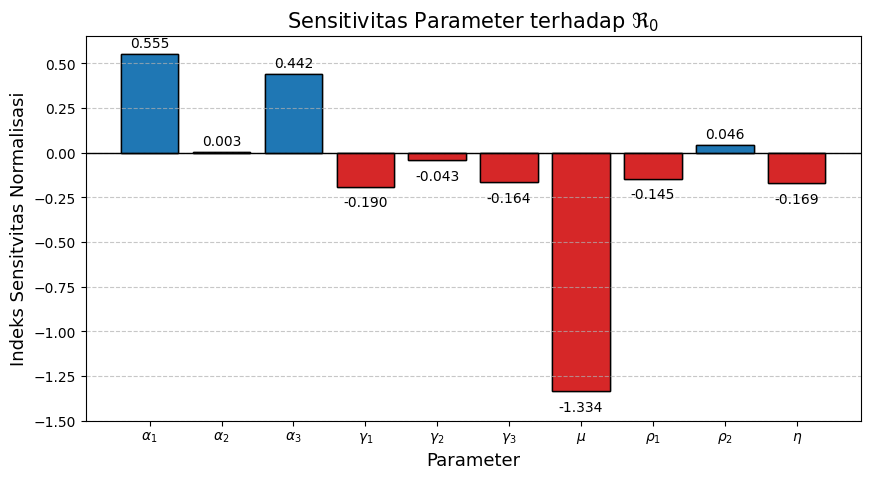

In [ ]:
# ==========================================
# VISUALISASI NORMALIZED SENSITIVITY INDEX
# ==========================================

# Simpan semua nilai sensitivitas yang sudah dihitung
sensitivity_values = {
    r'$\alpha_1$': float(sensitivity_alpha1_substituted),
    r'$\alpha_2$': float(sensitivity_alpha2_substituted),
    r'$\alpha_3$': float(sensitivity_alpha3_substituted),
    r'$\gamma_1$': float(sensitivity_gamma1_substituted),
    r'$\gamma_2$': float(sensitivity_gamma2_substituted),
    r'$\gamma_3$': float(sensitivity_gamma3_substituted),
    r'$\mu$': float(sensitivity_mu_substituted),
    r'$\rho_1$': float(sensitivity_rho1_substituted),
    r'$\rho_2$': float(sensitivity_rho2_substituted),
    r'$\eta$': float(sensitivity_eta_substituted)
}

# Ubah menjadi DataFrame
df_sensitivity = pd.DataFrame({
    'Parameter': list(sensitivity_values.keys()),
    'Sensitivity': list(sensitivity_values.values())
})

# MEMBUAT GRAFIK BATANG
plt.figure(figsize=(10,5))

# Warna: biru = positif, merah = negatif
colors = ['#1f77b4' if x > 0 else '#d62728'
          for x in df_sensitivity['Sensitivity']]

# Plot bar chart
plt.bar(
    df_sensitivity['Parameter'], df_sensitivity['Sensitivity'], color=colors, edgecolor='black'
)
bars = plt.bar(df_sensitivity['Parameter'], df_sensitivity['Sensitivity'], color=colors, edgecolor='black'
)

# Tambahkan label angka di atas batang
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 0.02 if height >= 0 else height - 0.05, f'{height:.3f}',
        ha='center', va='bottom' if height >= 0 else 'top', fontsize=10
    )
plt.axhline(0, color='black', linewidth=1) # garis y=0
plt.ylabel('Indeks Sensitvitas Normalisasi', fontsize=13)
plt.xlabel('Parameter', fontsize=13)
plt.title(r'Sensitivitas Parameter terhadap $\Re_0$', fontsize=15)
y_min = -1.4
y_max = max(df_sensitivity['Sensitivity'])
margin = 0.1
plt.ylim(y_min - margin, y_max + margin)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show() # tampilkan grafik

## Hubungan dengan $\mathfrak{R}_0$

### $\mathfrak{R}_0$ dengan $\alpha_1$

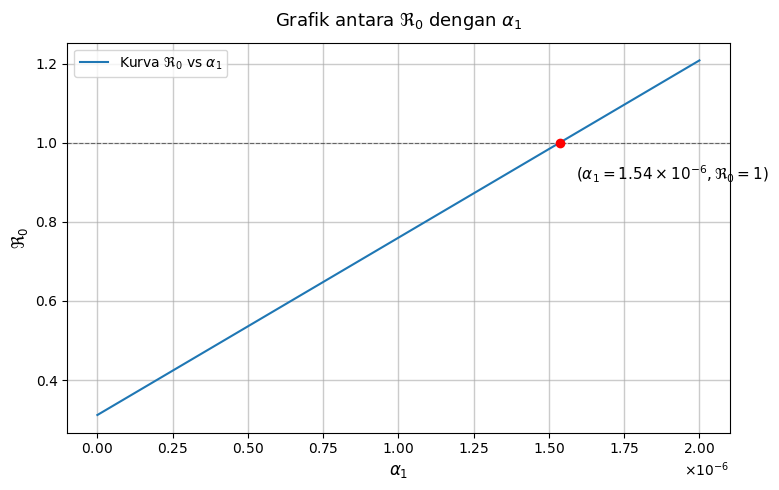

In [ ]:
from scipy.optimize import fsolve

# Definisi Parameter Dasar Sesuai Tabel
mu = 0.0135
alpha1_base =1e-6
alpha2 = 2e-8
alpha3_base = 1e-7
Omega = 1594
eta_base = 0.08
rho1_base = 0.12
rho2 = 0.06
gamma1 = 0.05
gamma2 = 0.1
gamma3 = 0.008


# Menghitung R0
def hitung_R0(alpha1, alpha3, eta, rho1):
    K1 = mu + gamma1 + rho1 + eta
    K2 = mu + gamma2 + rho2
    K3 = mu + gamma3

    pembilang = Omega * ((eta * (alpha2 * K3 + alpha3 * rho2)) + (K2 * (alpha1 * K3 + alpha3 * rho1)))
    penyebut = K1 * K2 * K3 * mu
    return pembilang / penyebut

# Mencari titik potong alpha 1 saat R0 = 1
def cari_akar_alpha1(x): return hitung_R0(x, alpha3_base, eta_base, rho1_base) - 1
# Menggunakan fsolve untuk mencari akar persamaan
potong_alpha1 = fsolve(cari_akar_alpha1, 5e-7)[0]
titik_alpha1 = np.linspace(min(0, potong_alpha1 * 1.2), max(2e-6, potong_alpha1 * 1.2), 100)
R0_alpha1 = hitung_R0(titik_alpha1, alpha3_base, eta_base, rho1_base)

# Fungsi Plot
def buat_plot(ax, x_vals, y_vals, potong_val, title, latex_simbol):
    # Plot garis utama biru
    ax.plot(x_vals, y_vals, color='tab:blue', linewidth=1.5, label=f'Kurva $\\Re_0$ vs ${latex_simbol}$')
    # Titik Merah saat R0 = 1
    ax.plot(potong_val, 1, 'ro', markersize=6, zorder=5)
    # Format Teks Anotasi (Notasi Ilmiah LaTeX)
    if abs(potong_val) < 0.01 and potong_val != 0:
        sci_str = f"{potong_val:.2e}"
        base, exp = sci_str.split('e')
        exp = int(exp) # Menghilangkan 0 ekstra di pangkat
        val_str = f"{base} \\times 10^{{{exp}}}"
    else:
        val_str = f"{potong_val:.4f}"
    anotasi = f'$({latex_simbol} = {val_str}, \\Re_0 = 1)$'
    # Menempatkan teks di kanan bawah titik merah
    ax.annotate(anotasi, xy=(potong_val, 1), xytext=(12, -15),
                textcoords='offset points', ha='left', va='top', fontsize=11, color='black')

    ax.set_title(title, fontsize=13, pad=12)
    ax.set_xlabel(f'${latex_simbol}$', fontsize=12)
    ax.set_ylabel(r'$\Re_0$', fontsize=12)
    ax.axhline(1, color='black', linestyle='--', linewidth=0.8, alpha=0.5) # Garis bantu horizontal R0=1
    ax.grid(True, which='both', linestyle='-', linewidth=1, color='darkgray', alpha=0.6)
    ax.legend(loc='best', fontsize=10)
    if max(abs(x_vals)) < 0.01:
        ax.ticklabel_format(style='sci', axis='x', scilimits=(0,0), useMathText=True)

# ===== Grafik R0 dengan alpha 1 =====
fig, ax = plt.subplots(figsize=(8, 5))
buat_plot(ax, titik_alpha1, R0_alpha1, potong_alpha1, r'Grafik antara $\Re_0$ dengan $\alpha_1$', r'\alpha_1')
plt.tight_layout()
plt.show()

### $\mathfrak{R}_0$ dengan $\alpha_3$

/tmp/ipykernel_611/3394555265.py:3: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  potong_alpha3 = fsolve(cari_akar_alpha3, 0.0)[0]


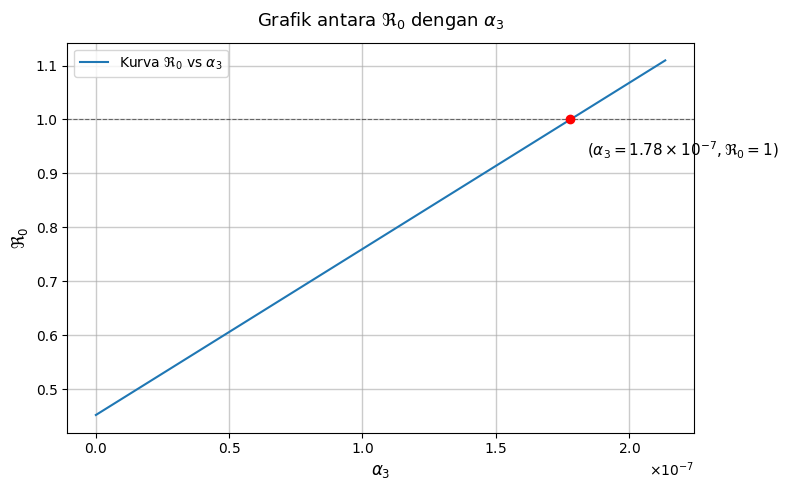

In [ ]:
# Mencari titik potong alpha 1 saat R0 = 1
def cari_akar_alpha3(x): return hitung_R0(alpha1_base, x, eta_base, rho1_base) - 1
potong_alpha3 = fsolve(cari_akar_alpha3, 0.0)[0]
titik_alpha3 = np.linspace(min(0, potong_alpha3 * 1.2), max(2e-9, potong_alpha3 * 1.2), 100)
R0_alpha3 = hitung_R0(alpha1_base, titik_alpha3, eta_base, rho1_base)

# ===== Grafik R0 dengan alpha 3
fig, ax = plt.subplots(figsize=(8, 5))
buat_plot(ax, titik_alpha3, R0_alpha3, potong_alpha3, r'Grafik antara $\Re_0$ dengan $\alpha_3$', r'\alpha_3')
plt.tight_layout()
plt.show()

### $\mathfrak{R}_0$ dengan $\rho_1$

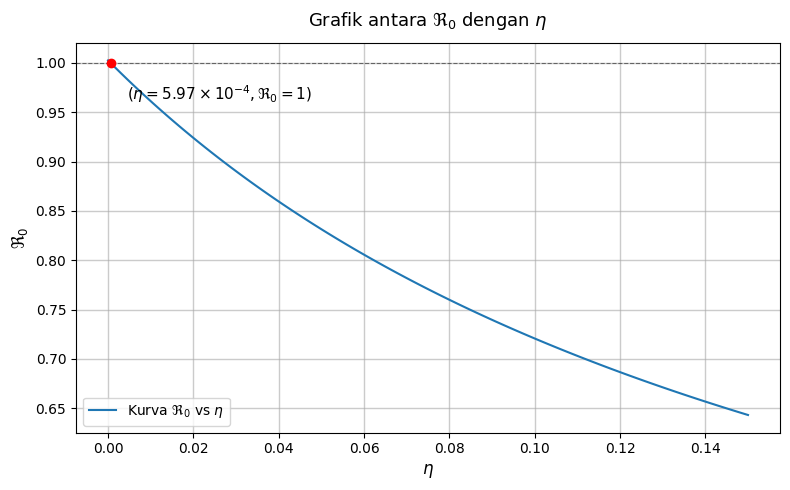

In [ ]:
# Mencari titik potong eta saat R0 = 1
def cari_akar_eta(x):    return hitung_R0(alpha1_base, alpha3_base, x, rho1_base) - 1
potong_eta    = fsolve(cari_akar_eta, 0.1)[0]
titik_eta    = np.linspace(min(0, potong_eta * 1.2), max(0.15, potong_eta * 1.2), 100)
R0_eta    = hitung_R0(alpha1_base, alpha3_base, titik_eta, rho1_base)

# ===== Grafik R0 dengan eta =====
fig, ax = plt.subplots(figsize=(8, 5))
buat_plot(ax, titik_eta, R0_eta, potong_eta, r'Grafik antara $\Re_0$ dengan $\eta$', r'\eta')
plt.tight_layout()
plt.show()

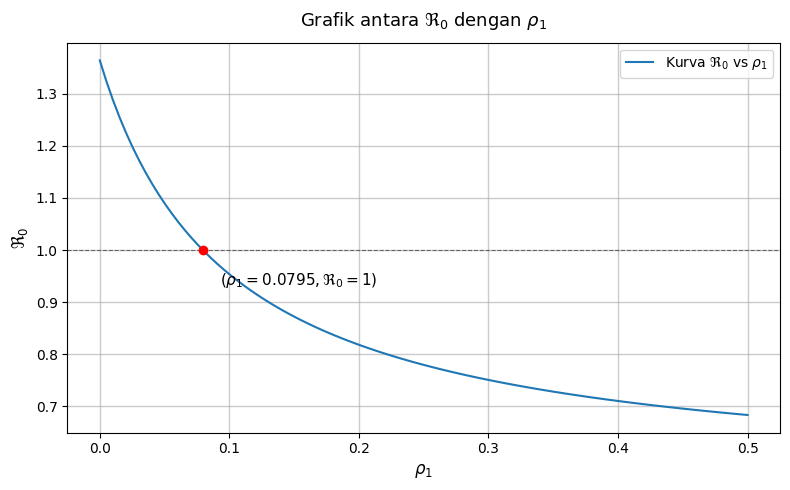

In [ ]:
# Mencari titik potong rho1 saat R0 = 1
gamma1 = 0.005
def cari_akar_rho1(x):    return hitung_R0(alpha1_base, alpha3_base, eta_base, x) - 1
potong_rho1    = fsolve(cari_akar_rho1, 0.1)[0]
titik_rho1 = np.linspace(0, max(0.5, potong_rho1 * 2.5), 100)
R0_rho1    = hitung_R0(alpha1_base, alpha3_base, eta_base, titik_rho1)

# ===== Grafik R0 dengan rho 1 =====
fig, ax = plt.subplots(figsize=(8, 5))
buat_plot(ax, titik_rho1, R0_rho1, potong_rho1, r'Grafik antara $\Re_0$ dengan $\rho_1$', r'\rho_1')
plt.tight_layout()
plt.show()

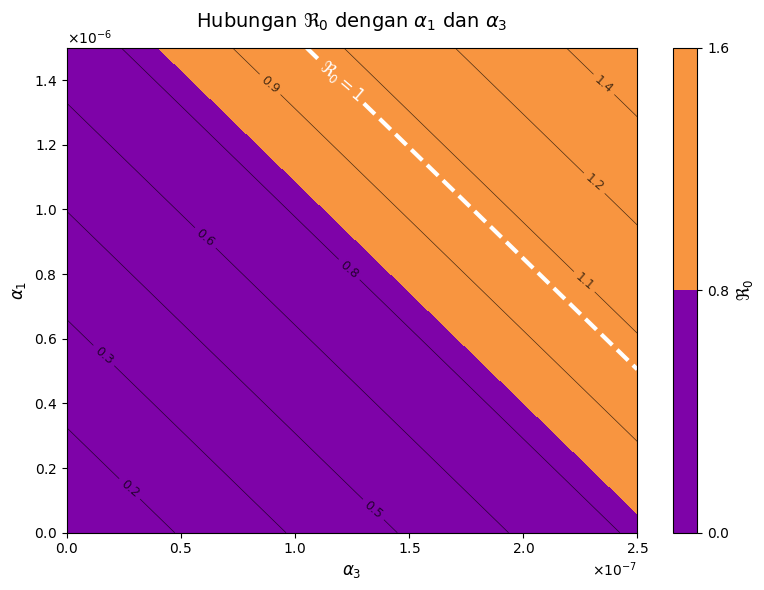

In [ ]:
# Definisi Parameter
mu = 0.0135
alpha1_base = 1e-6
alpha2_base = 2e-8
alpha3_base = 1e-7
Omega = 1594
eta_base = 0.08
rho1_base = 0.12
rho2_base = 0.06
gamma1 = 0.05
gamma2 = 0.1
gamma3 = 0.008

# 2. Fungsi R_0
def hitung_R0_2D(alpha1_val, alpha3_val, rho1_val):
    K1 = mu + gamma1 + rho1_val + eta_base
    K2 = mu + gamma2 + rho2_base
    K3 = mu + gamma3

    pembilang = Omega * (eta_base * (alpha2_base * K3 + alpha3_val * rho2_base) + K2 * (alpha1_val * K3 + alpha3_val * rho1_val))
    penyebut = K1 * K2 * K3 * mu
    return pembilang / penyebut

# Fungsi Plotting
def buat_plot_kontur_satuan(X, Y, Z, xlabel, ylabel, title, cmap):
    fig, ax = plt.subplots(figsize=(8, 6))
    # Membuat gradien warna kontur
    kontur_fill = ax.contourf(X, Y, Z, levels=1, cmap=cmap)
    # Menambahkan garis kontur tipis standar warna hitam
    kontur_line = ax.contour(X, Y, Z, levels=10, colors='black', linewidths=0.5, alpha=0.7)
    ax.clabel(kontur_line, inline=True, fontsize=9, fmt='%.1f')
    # Memunculkan Garis R_0 = 1
    if Z.min() <= 1.0 <= Z.max():
        kontur_r1 = ax.contour(X, Y, Z, levels=[1.0], colors='white', linewidths=3, linestyles='--')
        ax.clabel(kontur_r1, inline=True, fontsize=12, fmt=r'$\Re_0 = 1$')
    ax.set_title(title, fontsize=14, pad=15)
    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    cbar = plt.colorbar(kontur_fill, ax=ax)
    cbar.set_label(r'$\Re_0$', fontsize=12)
    ax.ticklabel_format(style='sci', axis='both', scilimits=(0,0), useMathText=True)
    plt.tight_layout()
    plt.show()

# Pengaturan Rentang
res = 200 # Resolusi titik dinaikkan agar garis sangat mulus
# Rentang sumbu
alpha3_b = np.linspace(0, 2.5e-7, res)
alpha1_b = np.linspace(0, 1.5e-6, res)
X_b, Y_b = np.meshgrid(alpha3_b, alpha1_b)
Z_b = hitung_R0_2D(alpha1_val=Y_b, alpha3_val=X_b, rho1_val=rho1_base)
buat_plot_kontur_satuan(X_b, Y_b, Z_b,
                        xlabel=r'$\alpha_3$',
                        ylabel=r'$\alpha_1$',
                        title=r'Hubungan $\Re_0$ dengan $\alpha_1$ dan $\alpha_3$',
                        cmap='plasma')

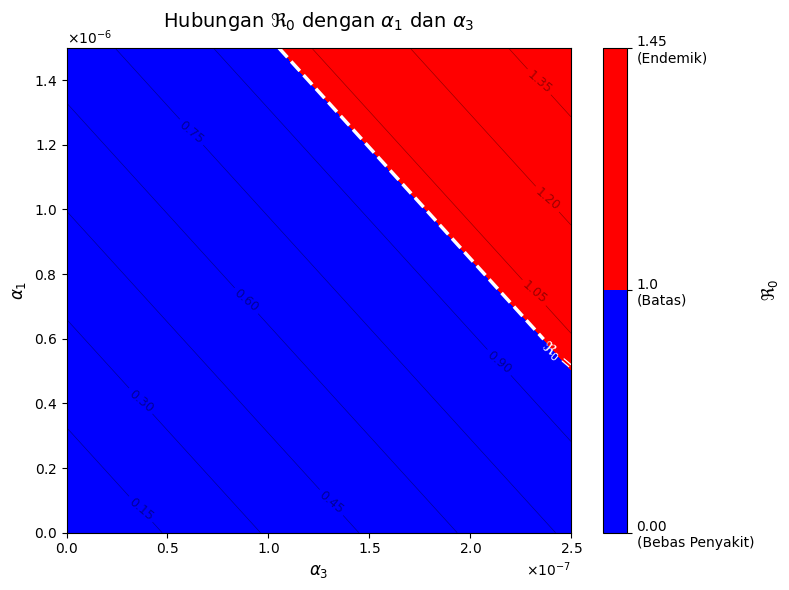

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# 1. Definisi Parameter (TETAP)
mu = 0.0135
alpha1_base = 1e-6
alpha2_base = 2e-8
alpha3_base = 1e-7
Omega = 1594
eta_base = 0.08
rho1_base = 0.12
rho2_base = 0.06
gamma1 = 0.05
gamma2 = 0.1
gamma3 = 0.008

# 2. Fungsi R_0 (TETAP)
def hitung_R0_2D(alpha1_val, alpha3_val, rho1_val):
    K1 = mu + gamma1 + rho1_val + eta_base
    K2 = mu + gamma2 + rho2_base
    K3 = mu + gamma3

    pembilang = Omega * (eta_base * (alpha2_base * K3 + alpha3_val * rho2_base) + K2 * (alpha1_val * K3 + alpha3_val * rho1_val))
    penyebut = K1 * K2 * K3 * mu
    return pembilang / penyebut

# 3. Fungsi Plotting Terbimbing
def buat_plot_kontur_satuan(X, Y, Z, xlabel, ylabel, title):
    fig, ax = plt.subplots(figsize=(8, 6))

    z_min = Z.min()
    z_max = Z.max()

    if z_min < 1.0 < z_max:
        levels = [z_min, 1.0, z_max]
        cmap_kustom = mcolors.ListedColormap(['blue', 'red'])
    else:
        levels = 10
        cmap_kustom = 'plasma'

    kontur_fill = ax.contourf(X, Y, Z, levels=levels, cmap=cmap_kustom)

    kontur_line = ax.contour(X, Y, Z, levels=10, colors='black', linewidths=0.5, alpha=0.4)
    ax.clabel(kontur_line, inline=True, fontsize=9, fmt='%.2f')

    # --- BAGIAN PERBAIKAN AGAR TULISAN R0=1 PASTI KELIHATAN ---
    if z_min <= 1.0 <= z_max:
        kontur_r1 = ax.contour(X, Y, Z, levels=[1.0], colors='white', linewidths=2.5, linestyles='--')
        # Format diubah menggunakan dictionary agar teks LaTeX terbaca sempurna
        teks_r1 = ax.clabel(kontur_r1, inline=True, fontsize=11, fmt={1.0: r'$\Re_0 = 1$'}, colors='white')


    # ---------------------------------------------------------

    ax.set_title(title, fontsize=14, pad=15)
    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)

    cbar = plt.colorbar(kontur_fill, ax=ax, ticks=[z_min, 1.0, z_max])
    cbar.set_label(r'$\Re_0$', fontsize=12)
    cbar.ax.set_yticklabels([f'{z_min:.2f}\n(Bebas Penyakit)', '1.0\n(Batas)', f'{z_max:.2f}\n(Endemik)'])

    ax.ticklabel_format(style='sci', axis='both', scilimits=(0,0), useMathText=True)
    plt.tight_layout()
    plt.show()

# 4. Pengaturan Rentang Eksperimen (TETAP)
res = 300
alpha3_b = np.linspace(0, 2.5e-7, res)
alpha1_b = np.linspace(0, 1.5e-6, res)
X_b, Y_b = np.meshgrid(alpha3_b, alpha1_b)
Z_b = hitung_R0_2D(alpha1_val=Y_b, alpha3_val=X_b, rho1_val=rho1_base)

# Memanggil Fungsi Plot
buat_plot_kontur_satuan(X_b, Y_b, Z_b,
                        xlabel=r'$\alpha_3$',
                        ylabel=r'$\alpha_1$',
                        title=r'Hubungan $\Re_0$ dengan $\alpha_1$ dan $\alpha_3$')